# Encontro 13 — Validação e oficina de projeto

**Modelagem Dinâmica Espacial · LambdaGeo/UFMA**

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lambdageo-edu/curso-modelagem-dinamica-espacial/blob/main/docs/notebooks/encontro13_validacao.ipynb)

Sem Python instalado? O selo acima abre este notebook no Google Colab, no navegador. Lá, use *Arquivo → Salvar uma cópia no Drive* antes de mudar qualquer coisa: sem a cópia, o que você escrever se perde ao fechar a página.

Até aqui comparamos o DisSModel e o DisSLUCC com o TerraME e o LuccME. Isso é **verificação**: o programa faz as contas que o modelo diz? Hoje fazemos a outra pergunta, a **validação**: o modelo se parece com o mundo? Para isso comparamos o mapa simulado com um mapa **observado** do mesmo ano.

A primeira parte é uma demonstração, com o lab15 (Mojuí dos Campos), que traz o desmatamento observado em 2004. A segunda é a oficina: cada um valida o próprio modelo com as mesmas funções.

1. simulado × observado: acertos, omissões e falsos alarmes;
2. quantidade e localização (Pontius e Millones, 2011);
3. modelos nulos: o modelo é melhor que não fazer nada? E que sortear?
4. a mesma comparação em resoluções mais grossas;
5. as funções para o seu projeto.

✏️ = responda.

## 0. Preparação

No Colab, a célula abaixo instala o DisSModel e o DisSLUCC (cerca de 1 minuto). No laboratório o ambiente já está instalado e ela não instala nada.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip install -q "dissmodel==0.6.6" "disslucc==0.5.0"

import contextlib, hashlib, io, time, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from dissmodel.core import Environment
from dissmodel.geo.raster.backend import RasterBackend
from disslucc import AllocationDClueSLike, DemandPreComputedValues, LogisticRegressionSpec, PotentialDLogisticRegression
from disslucc.validation import naive_allocation, pontius_millones

GOLDENS = "https://raw.githubusercontent.com/LambdaGeo/luccme-goldens/v1.1.0/sources/labs/data/"
ARQUIVOS = {
    "cs_moju.shp": "19fec700619036cfe9764339c974904647d2ea2f4342f95781b8a182e188c13b",
    "cs_moju.dbf": "e525edd9b1d02d400862bd6f3e8d3af7f6ad3afe89a1b1738c6e4c2eff0857aa",
    "cs_moju.shx": "8bcb68905d6e3d3a75847d1a00ff36d8a034e48691b6ecb62ae2eb859ec2033e",
    "cs_moju.prj": "622ed9a970750e2421b6f6f6e4bc159edf2ae2ba95cb628ba328bf5443c65252",
}

def baixar(nome, sha256, pasta=Path("dados_labs"), tentativas=5):
    destino = pasta / nome
    pasta.mkdir(exist_ok=True)
    for _ in range(tentativas):
        if destino.exists() and hashlib.sha256(destino.read_bytes()).hexdigest() == sha256:
            return destino
        try:
            with urllib.request.urlopen(GOLDENS + nome) as r:
                destino.write_bytes(r.read())
        except Exception:
            time.sleep(2)
    raise RuntimeError(f"{nome}: o arquivo baixado não confere com o hash publicado")

locais = {n: baixar(n, h) for n, h in ARQUIVOS.items()}
moju = gpd.read_file(locais["cs_moju.shp"])
print(len(moju), "células")

5914 células


O modelo é o lab15 com tolerância de 10 células, como nos encontros 11 e 12. A função devolve o mapa de desmatado simulado para 2004.

In [2]:
USOS = ["f", "d", "o"]
VARIAVEIS = ["media_decl", "dist_area_", "dist_br", "dist_curua", "dist_rios_", "dist_estra"]
DEMANDA = [[5706, 205, 3], [5658, 253, 3], [5611, 300, 3], [5563, 348, 3], [5516, 395, 3], [5468, 443, 3]]
POTENCIAL = [
    LogisticRegressionSpec(const=-2.34187976925989, elasticity=0.0, betas={
        "media_decl": -0.0272710076327129, "dist_area_": 4.30977432375496, "dist_br": 3.10319957497883,
        "dist_curua": 0.445414024051873, "dist_rios_": 47.3556329553235, "dist_estra": 38.4966894254506}),
    LogisticRegressionSpec(const=-0.100351497277102, elasticity=0.6, betas={
        "media_decl": 0.0581358851690861, "dist_area_": -0.974998890251365, "dist_br": -2.51650696123426,
        "dist_curua": -1.26742746441679, "dist_rios_": -40.3646901047482, "dist_estra": -23.0841140199094}),
    LogisticRegressionSpec(const=0.01, elasticity=0.5, betas={}),
]
linhas = moju["row"].astype(int).values
colunas = moju["col"].astype(int).values
lin, col = linhas - linhas.min(), colunas - colunas.min()
FORMA = (lin.max() + 1, col.max() + 1)


def simular_lab15():
    grade = RasterBackend(shape=FORMA)
    mascara = np.zeros(FORMA, dtype=np.float32); mascara[lin, col] = 1
    grade.set("mask", mascara)
    for c in USOS + VARIAVEIS:
        a = np.zeros(FORMA, dtype=np.float32); a[lin, col] = moju[c].astype(float).values
        grade.set(c, a)
    env = Environment(end_time=len(DEMANDA) - 1)
    dem = DemandPreComputedValues(annual_demand=DEMANDA, land_use_types=USOS)
    PotentialDLogisticRegression(backend=grade, potential_data=[POTENCIAL], land_use_types=USOS)
    AllocationDClueSLike(backend=grade, demand=dem, land_use_types=USOS, transition_matrix=[[[1, 1, 0], [0, 1, 0], [0, 0, 1]]],
                         cell_area=1.0, max_difference=10, max_iteration=1000, factor_iteration=0.0001)
    with contextlib.redirect_stdout(io.StringIO()):
        env.run()
    return np.asarray(grade.get("d"))[lin, col].astype(float)


inicial = moju["d"].values.astype(float)       # 1999
observado = moju["d04"].values.astype(float)   # 2004, observado
simulado = simular_lab15()                     # 2004, simulado
print(f"desmatado: 1999 {inicial.sum():.0f}, 2004 observado {observado.sum():.0f}, 2004 simulado {simulado.sum():.0f} células")

desmatado: 1999 205, 2004 observado 443, 2004 simulado 442 células


## 1. Simulado × observado

Uma célula que mudou pode ter mudado nos dois mapas (**acerto**), só no observado (**omissão**: o modelo não previu) ou só no simulado (**falso alarme**). A **figura de mérito** (Pontius et al., 2008) é a fração de acertos entre todas as células que mudaram em algum dos dois mapas: 100% seria acertar todas, 0% não acertar nenhuma.

In [3]:
def comparar_mudanca(inicial, simulado, observado):
    """Acertos, omissões, falsos alarmes e figura de mérito, sobre as células que mudaram."""
    mudou_sim = (simulado == 1) & (inicial == 0)
    mudou_obs = (observado == 1) & (inicial == 0)
    acertos = int((mudou_sim & mudou_obs).sum())
    omissoes = int((~mudou_sim & mudou_obs).sum())
    falsos = int((mudou_sim & ~mudou_obs).sum())
    return {"acertos": acertos, "omissões": omissoes, "falsos alarmes": falsos,
            "figura de mérito": acertos / (acertos + omissoes + falsos)}

resultado = comparar_mudanca(inicial, simulado, observado)
resultado

{'acertos': 63,
 'omissões': 179,
 'falsos alarmes': 174,
 'figura de mérito': 0.15144230769230768}

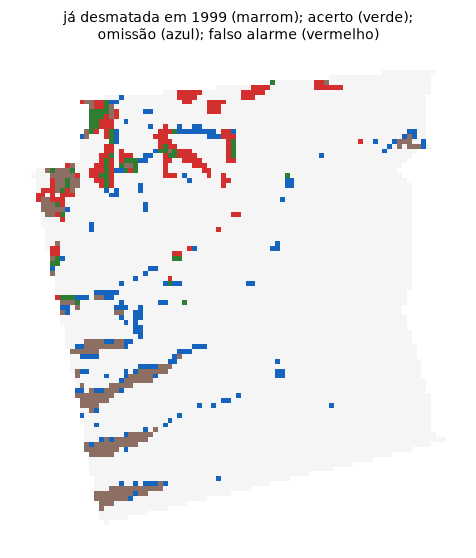

In [4]:
mudou_sim = (simulado == 1) & (inicial == 0)
mudou_obs = (observado == 1) & (inicial == 0)
tipo = np.select([inicial == 1, mudou_sim & mudou_obs, mudou_obs, mudou_sim], [1, 2, 3, 4], 0)
cores = ListedColormap(["#f5f5f5", "#8d6e63", "#2e7d32", "#1565c0", "#d32f2f"])
fig, ax = plt.subplots(figsize=(6.5, 6.5))
moju.assign(t=tipo).plot(column="t", cmap=cores, vmin=0, vmax=4, ax=ax)
ax.set_title("já desmatada em 1999 (marrom); acerto (verde);\nomissão (azul); falso alarme (vermelho)", fontsize=10)
ax.set_axis_off()

✏️ **Pergunta 1.** Os falsos alarmes estão longe das omissões, ou do lado delas? O que isso diz sobre o erro do modelo: errou a região, ou acertou a região e errou a célula?

## 2. Quantidade e localização

O erro total, em fração das células, se divide em duas partes (Pontius e Millones, 2011):

- **quantidade**: o modelo desmatou mais ou menos do que o observado?
- **localização**: com a quantidade certa, desmatou nas células erradas?

O DisSLUCC tem a função pronta, `pontius_millones`. Comparamos o modelo com o modelo nulo mais simples, a **persistência**: "nada muda", o mapa de 1999 repetido em 2004.

In [5]:
def decompor(previsto, observado):
    r = pontius_millones(previsto, observado)
    return {"erro total": r["total_disagreement"], "quantidade": r["quantity_disagreement"],
            "localização": r["allocation_disagreement"]}

pd.DataFrame({"lab15": decompor(simulado, observado), "persistência (nada muda)": decompor(inicial, observado)}).T.style.format("{:.2%}")

,erro total,quantidade,localização
lab15,6.04%,0.02%,6.02%
persistência (nada muda),4.16%,4.02%,0.14%


✏️ **Pergunta 2.** O modelo tem erro total **maior** que "nada muda". Como pode? Olhe as duas colunas de erro: de onde vem o erro de cada um? (Dica: quem não desmata nada não pode desmatar no lugar errado.)

## 3. O modelo é melhor que sortear?

A persistência erra a quantidade. Um modelo nulo mais justo acerta a quantidade e sorteia o lugar: desmata, entre as células de floresta, o mesmo número de células que o modelo desmatou, ao acaso. Se o modelo não for melhor que isso, o potencial não está ajudando. Usamos 20 sorteios, cada um com a sua semente.

Comparamos também com uma alocação "ingênua" do DisSLUCC (`naive_allocation`): ordena as células pelo potencial e desmata as primeiras, sem o laço de ajuste do CLUE-S.

In [6]:
novas = int(simulado.sum() - inicial.sum())
floresta = np.where((inicial == 0) & (moju["o"].values == 0))[0]


def sorteado(semente):
    mapa = inicial.copy()
    mapa[np.random.default_rng(semente).choice(floresta, novas, replace=False)] = 1
    return mapa

sorteios = [sorteado(s) for s in range(20)]
ingenuo = naive_allocation(moju, int(simulado.sum()), [POTENCIAL]).astype(float)

figuras = pd.DataFrame({
    "lab15 (CLUE-S)": comparar_mudanca(inicial, simulado, observado),
    "ordenação pelo potencial": comparar_mudanca(inicial, ingenuo, observado),
    "sorteio (média de 20)": pd.DataFrame([comparar_mudanca(inicial, m, observado) for m in sorteios]).mean(),
}).T
figuras.style.format({"figura de mérito": "{:.1%}", "acertos": "{:.0f}", "omissões": "{:.0f}", "falsos alarmes": "{:.0f}"})

,acertos,omissões,falsos alarmes,figura de mérito
lab15 (CLUE-S),63,179,174,15.1%
ordenação pelo potencial,63,179,174,15.1%
sorteio (média de 20),10,232,227,2.1%


✏️ **Pergunta 3.** Quantas vezes o lab15 é melhor que o sorteio? E o que a linha da ordenação pelo potencial diz sobre o laço de ajuste do CLUE-S **neste** lab?

## 4. Em mais de uma resolução

Errar uma célula de 500 m por uma vizinha conta como erro inteiro. Agrupando as células em blocos de 2 × 2, 4 × 4 e assim por diante, comparamos a área desmatada **por bloco**: um erro "ao lado" deixa de contar. Pontius et al. (2004) chamam de **resolução nula** aquela em que o modelo passa a errar menos que a persistência.

,lado do bloco (km),lab15,persistência,sorteio (média de 20)
bloco (células),,,,
1,0.5,6.04%,4.16%,7.83%
2,1.0,5.97%,4.16%,7.37%
4,2.0,5.53%,4.13%,6.46%
8,4.0,4.95%,4.09%,5.07%
16,8.0,4.01%,4.02%,3.78%
32,16.0,2.99%,4.02%,3.25%


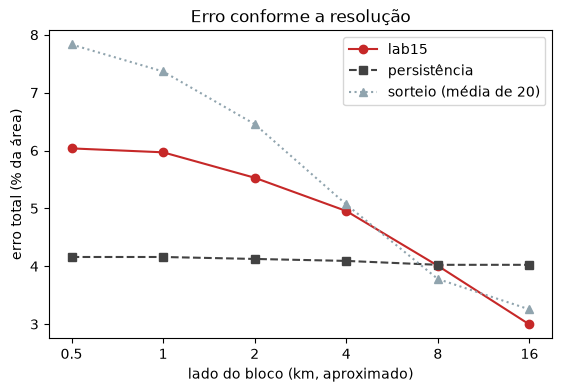

In [7]:
def erro_por_bloco(previsto, observado, linhas, colunas, tamanho):
    """Erro total e de quantidade com as células agrupadas em blocos tamanho × tamanho (em fração da área)."""
    t = pd.DataFrame({"p": previsto, "o": observado, "r": linhas // tamanho, "c": colunas // tamanho})
    blocos = t.groupby(["r", "c"])[["p", "o"]].sum()
    diferenca = blocos["p"] - blocos["o"]
    return abs(diferenca).sum() / len(previsto), abs(diferenca.sum()) / len(previsto)


TAMANHOS = [1, 2, 4, 8, 16, 32]
curvas = pd.DataFrame({
    "lab15": [erro_por_bloco(simulado, observado, linhas, colunas, k)[0] for k in TAMANHOS],
    "persistência": [erro_por_bloco(inicial, observado, linhas, colunas, k)[0] for k in TAMANHOS],
    "sorteio (média de 20)": [np.mean([erro_por_bloco(m, observado, linhas, colunas, k)[0] for m in sorteios]) for k in TAMANHOS],
}, index=pd.Index(TAMANHOS, name="bloco (células)"))
curvas.insert(0, "lado do bloco (km)", [k * 0.5 for k in TAMANHOS])

fig, ax = plt.subplots(figsize=(6.5, 4))
for nome, cor, marca in [("lab15", "#c62828", "o-"), ("persistência", "#424242", "s--"), ("sorteio (média de 20)", "#90a4ae", "^:")]:
    ax.plot(curvas["lado do bloco (km)"], curvas[nome] * 100, marca, color=cor, label=nome)
ax.set_xscale("log", base=2)
ax.set_xticks(curvas["lado do bloco (km)"], [f"{v:g}" for v in curvas["lado do bloco (km)"]])
ax.set(xlabel="lado do bloco (km, aproximado)", ylabel="erro total (% da área)", title="Erro conforme a resolução"); ax.legend()
curvas.style.format({"lado do bloco (km)": "{:.1f}", "lab15": "{:.2%}", "persistência": "{:.2%}", "sorteio (média de 20)": "{:.2%}"})

✏️ **Pergunta 4.** A partir de que tamanho de bloco o lab15 erra menos que a persistência? O que você diria a quem quer usar este modelo para decidir **qual propriedade** fiscalizar? E para decidir **qual região** do município priorizar?

> Atenção: não sabemos se os coeficientes do lab15 foram ajustados com o mapa de 2004 (encontro 11). Se foram, esta validação é otimista: o modelo está sendo comparado com dados que ajudaram a construí-lo. Uma validação honesta usa um mapa que não entrou no ajuste, por exemplo o de 2007 (`d07`), com a demanda estendida.

## 5. Para o seu projeto

As funções acima servem para qualquer modelo **discreto** (uma classe por célula, valores 0 e 1), desde que você tenha, para as mesmas células, o mapa inicial, o simulado e o observado, mais a linha e a coluna de cada célula. Com uma grade do DisSCube (encontro 10), as linhas e colunas vêm da posição na matriz:

```python
mascara = ~np.isnan(observado_2d)                   # células com dado
linhas_p, colunas_p = np.nonzero(mascara)
inicial_p, simulado_p, observado_p = inicial_2d[mascara], simulado_2d[mascara], observado_2d[mascara]

print(comparar_mudanca(inicial_p, simulado_p, observado_p))
print(decompor(simulado_p, observado_p), decompor(inicial_p, observado_p))
for k in [1, 2, 4, 8]:
    print(k, erro_por_bloco(simulado_p, observado_p, linhas_p, colunas_p, k),
             erro_por_bloco(inicial_p, observado_p, linhas_p, colunas_p, k))
```

Para um modelo **contínuo** (frações), `decompor` e `erro_por_bloco` funcionam como estão, porque trabalham com frações. A figura de mérito, não: ela conta células que mudaram, e numa célula com frações é preciso escolher a partir de quanto ganho ela "mudou" (por exemplo, 0,1).

## Oficina

Use o tempo que resta para rodar o seu modelo e validá-lo. A lista do encontro 12 diz o que precisa estar pronto. Para o seminário (encontros 14 e 15), traga:

- [ ] o mapa simulado e o observado, lado a lado;
- [ ] a tabela de quantidade e localização, com a persistência ao lado;
- [ ] a figura de mérito do modelo e a do sorteio;
- [ ] a curva de erro por resolução, e a resolução a partir da qual o modelo bate a persistência (se bater);
- [ ] uma frase sobre o que o modelo **não** consegue representar.